<a href="https://colab.research.google.com/github/bynak06-cell/Finance-and-Technology/blob/main/Tema_2_Carteras_Intro/src/SP_500_Diversification_Challenge_%E2%80%94_Find_the_Best_Diversifying_Pair.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import missingno as msno


In [ ]:
from io import StringIO
import requests

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
html = requests.get(url, headers ={"User-Agent": "Mozilla/5.0"}).text

sp500_tickers = pd.read_html(StringIO(html))[0]["Symbol"].to_list()

sp500_tickers = [ticker.replace(".","-") for ticker in sp500_tickers]

start = "2024-01-02"
end = "2025-12-31"

In [ ]:
data_raw = yf.download(sp500_tickers,start, end , auto_adjust=True)["Close"]

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
3 Failed downloads:
ERROR:yfinance:['VYLR', 'FDXF', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-01-02 -> 2025-12-31) (Yahoo error = "Data doesn\'t exist for startDate = 1704171600, endDate = 1767157200")')


In [ ]:
data = data_raw.copy()

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 501 entries, 2024-01-02 to 2025-12-30
Columns: 503 entries, A to ZTS
dtypes: float64(503)
memory usage: 1.9 MB


In [ ]:
data.head()

Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2024-01-02,135.917877,183.404022,144.645737,134.479996,103.134529,71.840385,327.203796,580.070007,185.602768,66.223305,...,31.840786,92.002762,57.849808,93.601601,109.875603,72.220001,122.321884,118.228020,267.980011,189.126083
2024-01-03,128.482788,182.030762,145.224960,133.419998,102.824692,73.162132,318.715332,571.789978,181.173187,66.560059,...,31.172680,91.448433,57.950069,94.388023,107.836044,68.629997,122.388260,117.331978,252.520004,185.623932
2024-01-04,128.326065,179.718933,146.130051,133.720001,104.195465,73.666107,317.932465,567.049988,178.402267,65.304039,...,30.742521,91.623474,58.086788,93.565018,108.580330,68.150002,121.999565,117.069000,252.970001,186.691879
2024-01-05,127.895027,178.997726,146.745453,135.979996,104.026459,73.038513,317.489166,564.599976,178.862503,64.448471,...,30.824890,93.023949,58.086788,93.848503,108.406357,66.959999,121.667763,116.854744,252.690002,187.471237
2024-01-08,130.657486,183.324982,146.102859,140.080002,105.528633,73.333298,321.007172,580.549988,181.192368,64.676025,...,31.163521,94.385513,57.950069,92.284821,109.082970,69.309998,121.952164,118.792908,261.089996,188.721954


<Axes: >

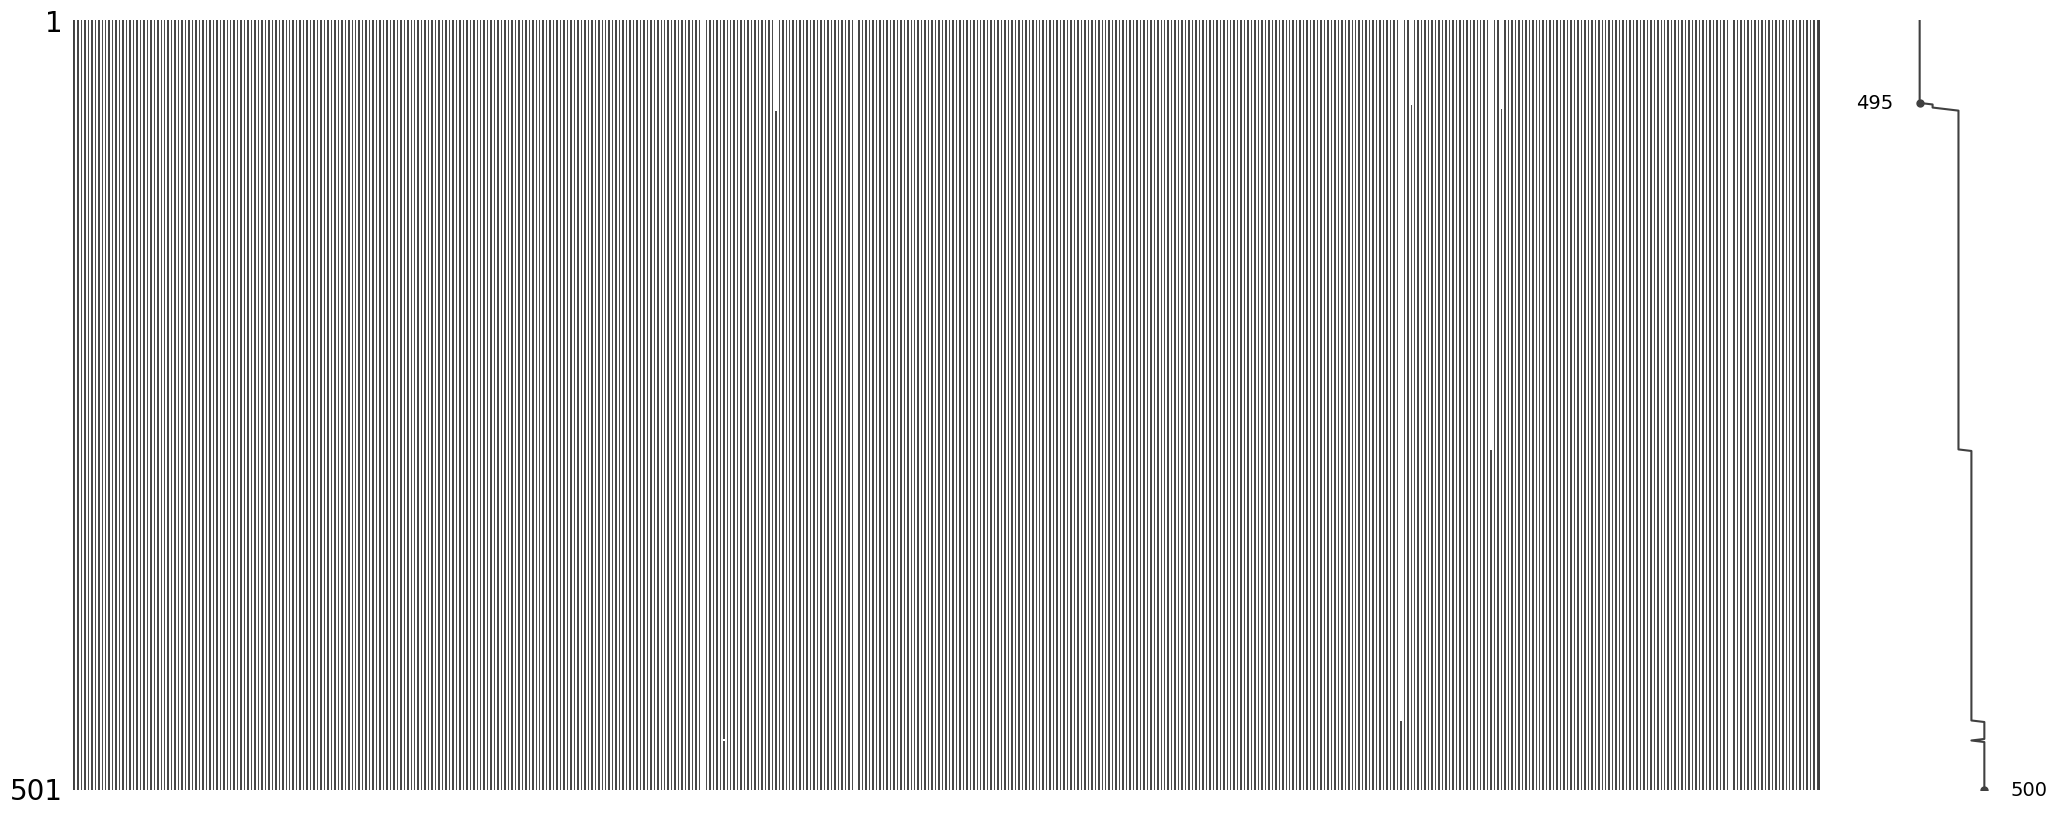

In [ ]:
msno.matrix(data)

In [ ]:
not_nan = ((data.notna().sum() / data.shape[0]) * 100).sort_values(ascending = False)

In [ ]:
not_nan.tail()

,0
Ticker,
SNDK,44.111776
Q,8.982036
HONA,0.000000
FDXF,0.000000
VYLR,0.000000


In [ ]:
validos = not_nan[not_nan > 90].index
data = data[validos]
data.shape

(501, 495)

In [ ]:
ret = np.log(data).diff().dropna()